# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [52]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [53]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [54]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [55]:
import random

numbers = list(range(10))

# тут двічі до set_seed()
print("До set_seed()")
print("1) randint:", random.randint(1, 100))
random.shuffle(numbers)
print("   shuffle:", numbers)

print("2) randint:", random.randint(1, 100))
random.shuffle(numbers)
print("   shuffle:", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# тут двічі після set_seed() з викликом set_seed() перед кожним генеруванням
print("\nЗ викликом set_seed() перед кожним разом")
set_seed()
print("1) randint:", random.randint(1, 100))
numbers = list(range(10))
set_seed()
random.shuffle(numbers)
print("   shuffle:", numbers)

set_seed()
print("2) randint:", random.randint(1, 100))
numbers = list(range(10))
set_seed()
random.shuffle(numbers)
print("   shuffle:", numbers)

# тут двічі без проміжних викликів set_seed()
print("\nБез проміжних викликів set_seed()")
print("1) randint:", random.randint(1, 100))
random.shuffle(numbers)
print("   shuffle:", numbers)

print("2) randint:", random.randint(1, 100))
random.shuffle(numbers)
print("   shuffle:", numbers)

До set_seed()
1) randint: 20
   shuffle: [4, 8, 7, 2, 6, 9, 0, 1, 5, 3]
2) randint: 6
   shuffle: [9, 3, 0, 7, 6, 4, 2, 8, 5, 1]
Seed зафіксовано: 42

З викликом set_seed() перед кожним разом
1) randint: 82
   shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
2) randint: 82
   shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

Без проміжних викликів set_seed()
1) randint: 76
   shuffle: [5, 8, 2, 1, 6, 3, 4, 0, 7, 9]
2) randint: 92
   shuffle: [3, 8, 9, 5, 2, 6, 0, 1, 4, 7]


Висновок щодо роботи set_seed():

Функція set_seed() фіксує початкову точку для генератора випадкових чисел.

На практиці це видно так:
Коли ми викликаємо set_seed() перед кожною дією, стан генератора постійно «скидається» на старт. Через це ми отримуємо абсолютно однакові результати, одне й те саме число в randint і однаковий порядок елементів після shuffle.
Якщо викликати set_seed() лише один раз на початку, то кожне наступне число чи перемішування вже буде іншим, але вся ця послідовність залишатиметься однаковою при кожному перезапуску програми.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [56]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [57]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [58]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [59]:
arange_arr = np.arange(0, 21, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18 20]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [60]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity, "ndim:", identity.ndim)
print(random_ints, "ndim:", random_ints.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] ndim: 2
[[6 3 7]
 [4 6 9]
 [2 6 7]] ndim: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [61]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = np.mean(scores)
std = np.std(scores)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [62]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [63]:
df = pd.DataFrame({
    "student": ["Олександр", "Владислав", "Денис", "Аліна", "Вікторія"],
    "score": [75, 88, 92, 65, 84]
})

top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)

     student  score
2      Денис     92
1  Владислав     88
4   Вікторія     84


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [64]:
def assign_grade(score):
    if score >= 90:
        return "A"
    elif score >= 75:
        return "B"
    else:
        return "C"

df["grade"] = df["score"].apply(assign_grade)
print(df)

     student  score grade
0  Олександр     75     B
1  Владислав     88     B
2      Денис     92     A
3      Аліна     65     C
4   Вікторія     84     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [65]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [66]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [67]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)

tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [68]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний градієнт:", x.grad.item())
print("Аналітичний градієнт :", 2 * n)

Автоматичний градієнт: 10.0
Аналітичний градієнт : 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [69]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f} (мінімум у x=3)")

x = 2.9654 (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

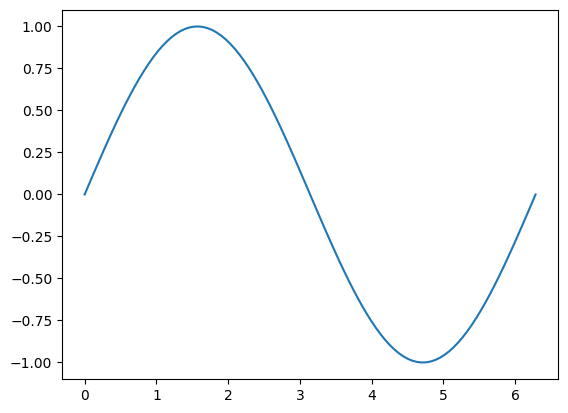

In [70]:
xs = np.linspace(0, 2 * np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

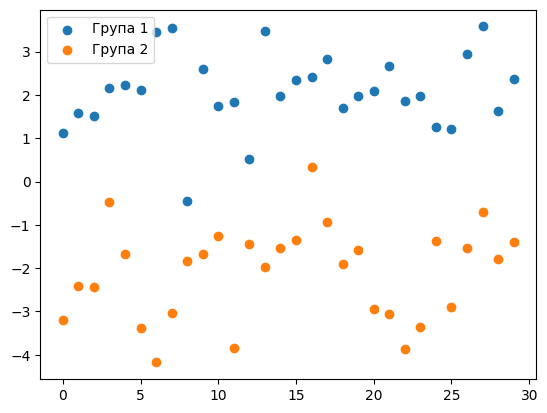

In [71]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

plt.scatter(range(len(group_a)), group_a, color="C0", label="Група 1")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Група 2")
plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [72]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

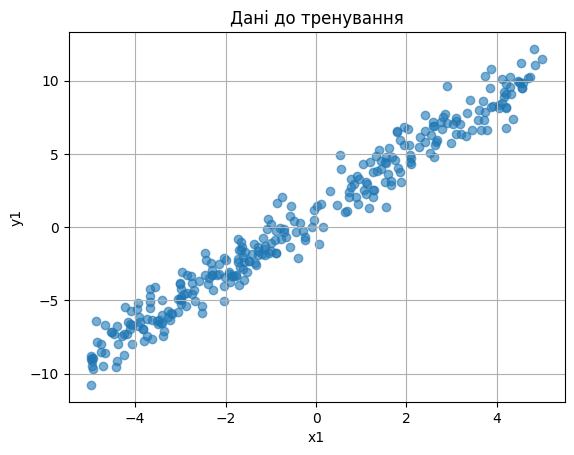

In [73]:
plt.scatter(x1, y1, alpha=0.6)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Дані до тренування")
plt.grid(True)
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [74]:
indices = torch.randperm(TASK1_N)
x_shuffled = x1[indices]
y_shuffled = y1[indices]

n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)

x_train1, y_train1 = x_shuffled[:n_train], y_shuffled[:n_train]
x_val1, y_val1 = x_shuffled[n_train:n_train + n_val], y_shuffled[n_train:n_train + n_val]
x_test1, y_test1 = x_shuffled[n_train + n_val:], y_shuffled[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [75]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


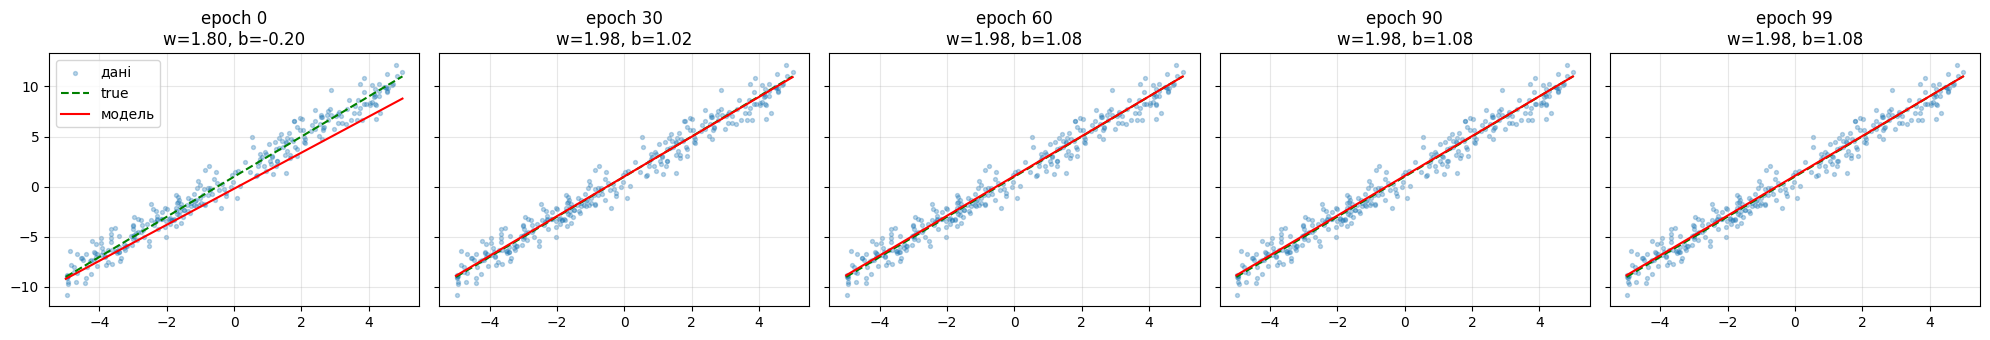

In [76]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Залежність втрати ваги за місяць від кількості кроків на день

Вхідна ознака (x): середня кількість кроків на день у тисячах (обираю в діапазоні від 2 до 20 тис. кроків).

Цільова змінна (y): зміна маси тіла за місяць (у кілограмах).

Параметри залежності ($y = w \cdot x + b$):
b = -0.5 — якщо людина майже не рухається (близько 0 кроків), через профіцит калорій вона в середньому набирає вагу (знак мінус позначає набір/відсутність скидання, або ж можна скинуто -0.5 кг).

w = 0.25 — кожна додаткова 1 000 щоденних кроків створює додатковий дефіцит і дозволяє спалити орієнтовно ще 0.25 кг за місяць. Наприклад, при 10 тис. кроків очікується приблизно 0.25 \times 10 - 0.5 = 2.0 кг скинутої ваги.

Шум ($\varepsilon$): індивідуальні особливості метаболізму, раціон харчування та рівень стресу, що додають випадковий розкид до результатів.

In [77]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import os

torch.manual_seed(42)

# параметри генерації
N_SAMPLES = 300
TRUE_W = 0.25
TRUE_B = -0.5

# x: від 2.0 до 20.0 тисяч кроків на день
x_data = torch.empty(N_SAMPLES, 1).uniform_(2.0, 20.0)
noise = 0.4 * torch.randn(N_SAMPLES, 1)
y_data = TRUE_W * x_data + TRUE_B + noise

# зберегаю у dataset.csv
df_steps = pd.DataFrame({
    "steps_thousands": x_data.squeeze().numpy(),
    "weight_loss_kg": y_data.squeeze().numpy()
})
csv_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
df_steps.to_csv(csv_path, index=False)
df_steps.to_csv("dataset.csv", index=False)
print(f"Датасет успішно збережено у: {csv_path}")

# спліт train/val/test (70% / 15% / 15%)
indices = torch.randperm(N_SAMPLES)
n_train = int(0.70 * N_SAMPLES)
n_val = int(0.15 * N_SAMPLES)

x_shuffled = x_data[indices]
y_shuffled = y_data[indices]

x_train, y_train = x_shuffled[:n_train], y_shuffled[:n_train]
x_val, y_val = x_shuffled[n_train:n_train + n_val], y_shuffled[n_train:n_train + n_val]
x_test, y_test = x_shuffled[n_train + n_val:], y_shuffled[n_train + n_val:]

class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

def train_model(model, x_tr, y_tr, epochs=300, lr=0.01):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        pred = model(x_tr)
        loss = criterion(pred, y_tr)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model

def evaluate_model(model, x_eval, y_eval):
    model.eval()
    criterion = nn.MSELoss()
    with torch.no_grad():
        pred = model(x_eval)
        loss = criterion(pred, y_eval)
    return loss.item()

model = LinearRegressionModel()
model = train_model(model, x_train, y_train)

test_loss = evaluate_model(model, x_test, y_test)
print(f"Тестовий MSE: {test_loss:.4f}")
print(f"Натреновані параметри: w = {model.linear.weight.item():.4f}, b = {model.linear.bias.item():.4f}")

Датасет успішно збережено у: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
Тестовий MSE: 0.2342
Натреновані параметри: w = 0.1954, b = 0.2408


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [78]:
pt_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(model.state_dict(), pt_path)
torch.save(model.state_dict(), "model.pt")

print(f"Модель успішно збережена у: {pt_path}")

Модель успішно збережена у: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [79]:
!pip install -q gradio
import gradio as gr

inference_model = LinearRegressionModel()
inference_model.load_state_dict(torch.load("model.pt"))
inference_model.eval()

def predict_weight_loss(steps_thousands):
    input_t = torch.tensor([[float(steps_thousands)]], dtype=torch.float32)
    with torch.no_grad():
        prediction = inference_model(input_t).item()
    return f"{prediction:.2f} кг"

demo = gr.Interface(
    fn=predict_weight_loss,
    inputs=gr.Slider(minimum=2, maximum=20, step=0.5, value=10, label="Тисяч кроків на день"),
    outputs=gr.Textbox(label="Очікуване скидання ваги за місяць"),
    title="Калькулятор втрати ваги від кількості кроків"
)

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```